In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

trainFile = "../../../data/trainDataset/train.csv"
testFile = "../../../data/testDataset/test.csv"

df = pd.read_csv(trainFile)
df_test = pd.read_csv(testFile)

# 2. Data Cleaning: Dropping Corrupted & Fully Missing Rows
We identified rows with missing values across critical transaction attributes (such as 'Total a Pagar'). Because they provide no predictive signal, these corrupted records were removed from the training dataset.

In [20]:
outputFile = "../../../data/trainDataset/train_2.csv"
outputFile_test = "../../../data/testDataset/test_2.csv"

df_clean = df.dropna(subset=['Total a Pagar']).copy()

df_clean.to_csv(outputFile, index=False)


print(f"Dataset cleaned saved successfully to: {outputFile}")


Dataset cleaned saved successfully to: ../../../data/trainDataset/train_2.csv


Following the detailed exploratory analysis in Section 1.4, an inspection of the feature distributions revealed anomalous negative values across several numeric attributes where business logic strictly mandates non-negative domains (specifically ⁠ days_since_previous_purchase ⁠, ⁠ prior_mean_purchase_value ⁠, ⁠ prior_mean_gap_days ⁠, and ⁠ spend_365d ⁠). 

In [21]:
non_negative = [
    "days_since_previous_purchase", 
    "prior_mean_purchase_value", 
    "prior_mean_gap_days", 
    "spend_365d"
]

# Converter valores negativos nestas colunas para NaN
df_clean[non_negative] = df_clean[non_negative].mask(df_clean[non_negative] < 0)
df_test[non_negative] = df_test[non_negative].mask(df_test[non_negative] < 0)

# Guardar o dataset limpo
df_clean.to_csv(outputFile, index=False)
df_test.to_csv(outputFile_test, index=False)

print(f"Dataset cleaned saved successfully to: {outputFile}")
print(f"Test dataset cleaned saved successfully to: {outputFile_test}")

Dataset cleaned saved successfully to: ../../../data/trainDataset/train_2.csv
Test dataset cleaned saved successfully to: ../../../data/testDataset/test_2.csv


To validate the success of the domain cleaning step, we verify the distribution of missing (`NaN`) and negative values across the strictly non-negative features. 


In [22]:
# Lista das colunas não-negativas por regra de negócio
non_negative = [
    "days_since_previous_purchase", 
    "prior_mean_purchase_value", 
    "prior_mean_gap_days", 
    "spend_365d"
]

# Tabela de validação de valores omissos (NaN) e negativos restantes
def summarize_validation(df_clean, non_negative):
    summary = pd.DataFrame({
        'Total de NaNs': df_clean[non_negative].isna().sum(),
        'Percentagem de NaNs (%)': (df_clean[non_negative].isna().mean() * 100).round(2),
        'Negativos Restantes (< 0)': (df_clean[non_negative] < 0).sum()
    })
    return summary

validation_summary = summarize_validation(df_clean, non_negative)
validation_summary_test = summarize_validation(df_test, non_negative)

print("=== CONFIRMAÇÃO DE NULOS E NEGATIVOS EM DF_CLEAN ===")
print(validation_summary)
print("\n=== CONFIRMAÇÃO DE NULOS E NEGATIVOS EM DF_CLEAN_TEST ===")
print(validation_summary_test)


=== CONFIRMAÇÃO DE NULOS E NEGATIVOS EM DF_CLEAN ===
                              Total de NaNs  Percentagem de NaNs (%)  \
days_since_previous_purchase            812                    12.55   
prior_mean_purchase_value               813                    12.57   
prior_mean_gap_days                    1259                    19.46   
spend_365d                              210                     3.25   

                              Negativos Restantes (< 0)  
days_since_previous_purchase                          0  
prior_mean_purchase_value                             0  
prior_mean_gap_days                                   0  
spend_365d                                            0  

=== CONFIRMAÇÃO DE NULOS E NEGATIVOS EM DF_CLEAN_TEST ===
                              Total de NaNs  Percentagem de NaNs (%)  \
days_since_previous_purchase             54                     5.48   
prior_mean_purchase_value                54                     5.48   
prior_mean_gap_days  

____________________________________________________________________________________________________________________________________________________________________________________

## 2.1 Verification of Missing Value Removal
Verification of Missing Value Removal
To confirm the success of the data cleaning step, we re-evaluated the count of missing values (NaN) in the 'Total a Pagar' column within the cleaned dataset (df_clean), dynamically calculating the exact number of dropped records using the difference in dataset lengths.

In [23]:
# Verify directly if there are still null values in that column (should return 0)
print("NA Values in 'Total a Pagar':", df_clean['Total a Pagar'].isnull().sum())

# Dynamic calculation formula showing rows before, after, and total removed (~65 rows / 1%)
removed_rows_count = len(df) - len(df_clean)
print(f"Rows before: {len(df)} | Rows after: {len(df_clean)} | Removed rows: {removed_rows_count}")


NA Values in 'Total a Pagar': 0
Rows before: 6534 | Rows after: 6469 | Removed rows: 65


**Conclusion:** Removing the 65 corrupted rows ($\approx 1%$ of the total dataset) that lacked vital Total a Pagar (train dataset) values guarantees that subsequent statistical calculations and model training operate exclusively on complete transaction records, preventing artificial distortion or model bias.

____________________________________________________________________________________________________________________________________________________________________________________

## 2.2. Feature Type Separation & Exclusions
To prepare the dataset for model preprocessing and feature encoding, we systematically divide our attributes into distinct functional groups:

1. **Excluded Features (`identifiers` & `target`):** 
   * Primary transaction identifiers (`ID`) and customer keys (`customer_id`) are excluded to prevent data leakage and memorization (*overfitting*).
   * Raw date strings (`purchase_date`) are set aside after extracting engineered temporal features.
   * The target variable (`repeat_purchase_90d`) is isolated from the predictors ($X$).

2. **Numeric Features (`numeric`):** 
   * Dynamically selected continuous and discrete numerical indicators (e.g., spending metrics, historical purchase counts, and temporal gaps) that will undergo missing value imputation and scaling.

3. **Categorical Features (`categorical`):** 
   * Dynamically identified non-numeric attributes (e.g., payment types, sales agents, zones, warehouse locations) designated for categorical encoding (*One-Hot / Frequency Encoding*).

This automated partitioning ensures code scalability and seamless integration with `ColumnTransformer` pipelines.


In [24]:
# Identifiers and dates that MUST NOT be used for model training
identifiers = ["ID", "customer_id", "purchase_date"]
target = "repeat_purchase_90d"

# Automatic separation between numerical and categorical variables
def get_numeric_categorical(df, identifiers, target):
    numeric = [
        c for c in df.columns 
        if c not in identifiers + [target] and pd.api.types.is_numeric_dtype(df[c])
    ]
    
    categorical = [
        c for c in df.columns 
        if c not in identifiers + [target] + numeric
    ]
    
    return numeric, categorical

numeric_train, categorical_train = get_numeric_categorical(df_clean, identifiers, target)
numeric_test, categorical_test = get_numeric_categorical(df_test, identifiers, target)

# Validation output
print(f"Total features (Train): {df_clean.shape[1]} | Numeric: {len(numeric_train)} | Categorical: {len(categorical_train)}")
print(f"Total features (Test): {df_test.shape[1]} | Numeric: {len(numeric_test)} | Categorical: {len(categorical_test)}")

Total features (Train): 39 | Numeric: 29 | Categorical: 6
Total features (Test): 38 | Numeric: 29 | Categorical: 6


**Conclusions:** Explicitly separating primary transaction keys and raw identifiers (ID, customer_id, purchase_date) from numerical and categorical features ensures strict adherence to machine learning best practices. By isolating these non-predictive attributes before model training, we prevent accidental data leakage, avoid dimensionality inflation from unique identifiers, and guarantee that only valid, analytically sound predictors enter the feature matrix.

____________________________________________________________________________________________________________________________________________________________________________________

## 2.3. Handling Structural Missing Values (MNAR)

**Structural Missing Values:** Missingness in purchase history features is not random (Missing Not At Random — MNAR), as it is directly driven by **New Customers / First-Time Buyers**. Features such as `days_since_previous_purchase`, `prior_mean_purchase_value`, `prior_mean_gap_days`, and `prior_std_gap_days` exhibit high missingness rates for this reason.

* We created the binary flag is_first_purchase and applied strategic imputation (0 for deviations/averages and -1 as a temporal indicator).

In [25]:
import pandas as pd

inputFileTrain = "../../../data/trainDataset/train_2.csv"
inputFileTest = "../../../data/testDataset/test_2.csv"
outputFileTrain = "../../../data/trainDataset/train_2_3.csv"
outputFileTest = "../../../data/testDataset/test_2_3.csv"


def process_missing_values(input_file, output_file, dataset_label="Dataset"):
  # Carregar dataset
  df_clean = pd.read_csv(input_file)

  # Create a binary flag for new customers (First Purchase)
  df_clean['is_first_purchase'] = (
      df_clean['days_since_previous_purchase'].isnull().astype(int)
  )

  # Zero imputation for variation/deviation/mean columns that depend on multiple purchases
  zero_impute_cols = [
      'prior_std_purchase_value',
      'prior_std_gap_days',
      'prior_mean_gap_days',
  ]
  df_clean[zero_impute_cols] = df_clean[zero_impute_cols].fillna(0)

  # Indicator value imputation (-1) for time counts and averages of new customers
  indicator_impute_cols = [
      'days_since_previous_purchase',
      'prior_mean_purchase_value',
      'prior_min_purchase_value',
      'prior_max_purchase_value',
  ]
  df_clean[indicator_impute_cols] = df_clean[indicator_impute_cols].fillna(-1)

  # Guardar ficheiro processado
  df_clean.to_csv(output_file, index=False)

  # Imprimir mensagens de validação
  print(f"=== Processing {dataset_label} ===")
  print(f"Dataset read from: {input_file}")
  print(f"Dataset saved successfully to: {output_file}")

  # Validation of New Customer Flag and Imputations
  new_customers = df_clean['is_first_purchase'].sum()
  print(
      f"[2] Flag 'is_first_purchase': {new_customers} new customers identified"
      f" ({(new_customers/len(df_clean))*100:.1f}%)"
  )

  minus_one_counts = (df_clean[indicator_impute_cols] == -1).sum().to_dict()
  print(f"-> -1 Valuing applied per column: {minus_one_counts}\n")

  return df_clean


# Run processing for both Train and Test datasets
df_train_clean = process_missing_values(
    inputFileTrain, outputFileTrain, dataset_label="Train"
)
df_test_clean = process_missing_values(
    inputFileTest, outputFileTest, dataset_label="Test"
)


=== Processing Train ===
Dataset read from: ../../../data/trainDataset/train_2.csv
Dataset saved successfully to: ../../../data/trainDataset/train_2_3.csv
[2] Flag 'is_first_purchase': 812 new customers identified (12.6%)
-> -1 Valuing applied per column: {'days_since_previous_purchase': 812, 'prior_mean_purchase_value': 813, 'prior_min_purchase_value': 603, 'prior_max_purchase_value': 603}

=== Processing Test ===
Dataset read from: ../../../data/testDataset/test_2.csv
Dataset saved successfully to: ../../../data/testDataset/test_2_3.csv
[2] Flag 'is_first_purchase': 54 new customers identified (5.5%)
-> -1 Valuing applied per column: {'days_since_previous_purchase': 54, 'prior_mean_purchase_value': 54, 'prior_min_purchase_value': 22, 'prior_max_purchase_value': 22}



**Temporal Trend & Seasonality Analysis: Monthly Sales Volume**
To empirically verify whether purchasing behavior exhibits seasonal trends over time, we aggregate transaction volumes by month. This visualization helps confirm if temporal feature decomposition (such as purchase_month and purchase_quarter) captures meaningful variance in customer activity.

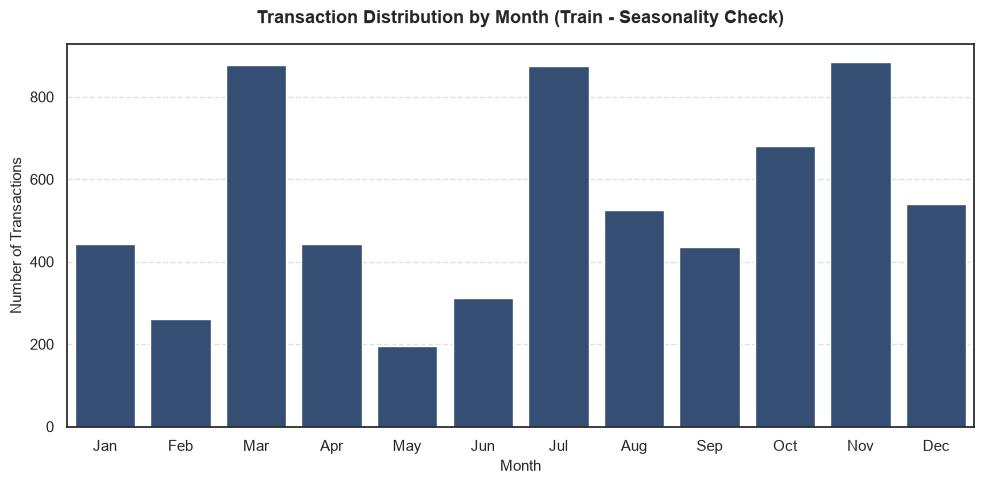

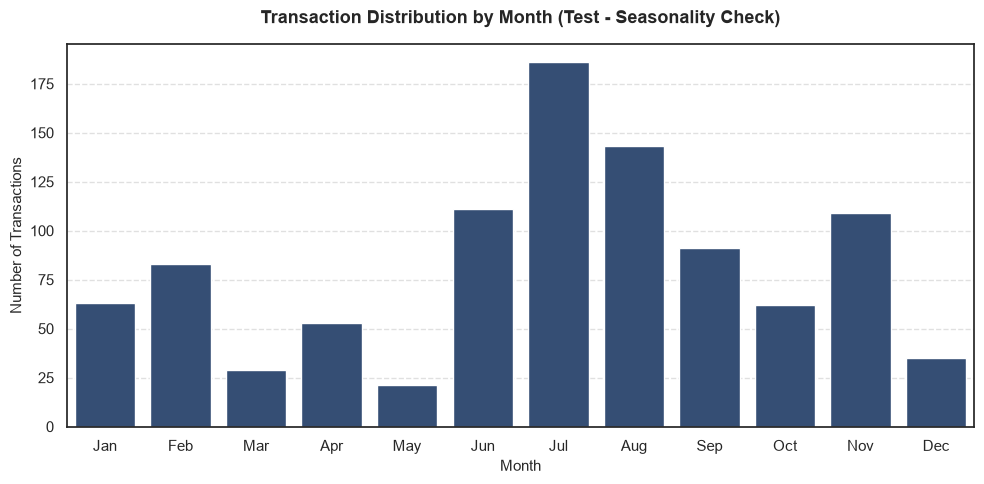

In [26]:
def plot_monthly_distribution(dataframe, dataset_label="Train"):
  # Ensure purchase_date is datetime for plotting
  df_temp_plot = dataframe.dropna(subset=["purchase_date"]).copy()
  df_temp_plot["purchase_date"] = pd.to_datetime(
      df_temp_plot["purchase_date"]
  )

  # Extract month name or number for histogram grouping
  df_temp_plot["month_name"] = df_temp_plot["purchase_date"].dt.strftime("%b")
  month_order = [
      "Jan",
      "Feb",
      "Mar",
      "Apr",
      "May",
      "Jun",
      "Jul",
      "Aug",
      "Sep",
      "Oct",
      "Nov",
      "Dec",
  ]

  # Plotting the histogram / countplot
  plt.figure(figsize=(10, 5))
  sns.countplot(
      data=df_temp_plot,
      x="month_name",
      order=month_order,
      color="#2b4c7e",
      zorder=2,
  )

  plt.title(
      f"Transaction Distribution by Month ({dataset_label} - Seasonality"
      " Check)",
      fontsize=13,
      fontweight="bold",
      pad=15,
  )
  plt.xlabel("Month", fontsize=11)
  plt.ylabel("Number of Transactions", fontsize=11)
  plt.grid(axis="y", linestyle="--", alpha=0.6)
  plt.tight_layout()

  plt.show()


# Chamada da função para Treino e Teste
plot_monthly_distribution(df, dataset_label="Train")
plot_monthly_distribution(df_test, dataset_label="Test")


**Conclusions: Handling Structural Missing Values (MNAR) & Seasonality Analysis**
* **Handling Structural Missingness (MNAR):** Because missing values in historical purchase variables are structural and Missing Not At Random (MNAR)—specifically representing new customers making their first purchase—naive imputation methods would severely distort the dataset's reality. Introducing the is_first_purchase flag and applying strategic domain-specific replacements (-1 for temporal/monetary indicators and 0 for variance/gap metrics) successfully preserved the unique behavioral profile of first-time buyers.
* **Temporal Seasonality Analysis:** The monthly transaction distribution histogram clearly reveals pronounced cyclical fluctuations in sales volume across the year. Specifically, prominent transaction surges occur during specific peak periods (such as March, July, October, and November/December), contrasting sharply with lower volumes in intermediate months. This distinct seasonal variance provides empirical justification for the subsequent feature engineering steps, confirming that decomposing raw dates into granular temporal predictors (purchase_month, purchase_quarter, and is_weekend) will supply tree-based models with meaningful behavioral patterns to predict repeat purchases accurately.

____________________________________________________________________________________________________________________________________________________________________________________

## 2.4. Inconsistency Values 

### 2.4.1. In `prior_mean_purchase_value` feature
This code verifies whether the stored values for `prior_mean_purchase_value` are correct by comparing them against the calculated mean ($\text{prior\_total\_spend} / \text{prior\_purchase\_count}$). If any inconsistencies or system errors are found, the recorded value is replaced with the exact calculated value.




In [27]:

inputFileTrain = "../../../data/trainDataset/train_2_3.csv"
outputFileTrain = "../../../data/trainDataset/train_2_4_1.csv"

inputFileTest = "../../../data/testDataset/test_2_3.csv"
outputFileTest = "../../../data/testDataset/test_2_4_1.csv"


def correct_prior_mean_purchase_value(
    input_file, output_file, dataset_label="Dataset"
):
  # 1. Load dataset
  df = pd.read_csv(input_file)

  # 2. Safely calculate the mean purchase value (avoiding division by zero)
  # If prior_purchase_count is 0 or NaN, keep NaN/indicator value (-1)
  calculated_mean = np.where(
      (df["prior_purchase_count"] > 0) & (df["prior_total_spend"].notna()),
      df["prior_total_spend"] / df["prior_purchase_count"],
      df[
          "prior_mean_purchase_value"
      ],  # Keep existing value (e.g., -1 for first purchases)
  )

  # 3. Identify mismatches using a small tolerance (1e-4) to account for floating-point rounding
  mismatch_mask = (df["prior_purchase_count"] > 0) & (
      ~np.isclose(
          df["prior_mean_purchase_value"],
          calculated_mean,
          atol=1e-4,
          equal_nan=True,
      )
  )

  # 4. Count and replace the mismatched cells with the calculated value
  mismatches_count = mismatch_mask.sum()

  df.loc[mismatch_mask, "prior_mean_purchase_value"] = calculated_mean[
      mismatch_mask
  ]

  # 5. Save the updated dataset
  df.to_csv(output_file, index=False)

  print(f"=== Processing {dataset_label} ===")
  print(f"Correction complete!")
  print(f"• Total cells updated: {mismatches_count}")
  print(f"• Dataset read from: {input_file}")
  print(f"• Dataset saved successfully to: {output_file}\n")

  return df


# Executar a correção para os datasets de Treino e Teste
df_train_clean = correct_prior_mean_purchase_value(
    inputFileTrain, outputFileTrain, dataset_label="Train"
)
df_test_clean = correct_prior_mean_purchase_value(
    inputFileTest, outputFileTest, dataset_label="Test"
)


=== Processing Train ===
Correction complete!
• Total cells updated: 272
• Dataset read from: ../../../data/trainDataset/train_2_3.csv
• Dataset saved successfully to: ../../../data/trainDataset/train_2_4_1.csv

=== Processing Test ===
Correction complete!
• Total cells updated: 41
• Dataset read from: ../../../data/testDataset/test_2_3.csv
• Dataset saved successfully to: ../../../data/testDataset/test_2_4_1.csv



#### Summary of Correction Results
* **Data Integrity Restored:** A total of **272 cells** exhibiting mathematical inconsistencies or severe system corruptions were identified and corrected.
* **Deterministic Baseline:** By replacing these erroneous entries with their exact calculated values ($\text{prior\_total\_spend} / \text{prior\_purchase\_count}$), we successfully eliminated data noise without distorting genuine transactional distributions.
* **Pipeline Readiness:** The feature `prior_mean_purchase_value` is now fully reconciled and clean, establishing a robust foundation for downstream outlier treatment and model training.


### 2.4.2. In spend_365d feature
Deterministic Cleaning of `spend_365d` System Placeholder Values.


In [28]:
# 1. Define input and output file paths
inputFileTrain = "../../../data/trainDataset/train_2_4_1.csv"
outputFileTrain = "../../../data/trainDataset/train_2_4_2.csv"

inputFileTest = "../../../data/testDataset/test_2_4_1.csv"
outputFileTest = "../../../data/testDataset/test_2_4_2.csv"


def correct_spend_365d(input_file, output_file, dataset_label="Dataset"):
  # Load dataset from previous stage
  df_clean = pd.read_csv(input_file)

  # Count initial corrupted entries before correction
  corrupted_before = (df_clean['spend_365d'] >= 1e8).sum()

  # 2. Define logical function to reconstruct the exact value of spend_365d
  def recalculate_spend_365d(row):
    # Check for data corruption or domain inconsistency
    if row['spend_365d'] >= 1e8 or row['spend_365d'] > row['prior_total_spend']:
      # Case 1: No purchases in the last year
      if row['purchase_count_365d'] == 0:
        return 0.0
      # Case 2: All historical purchases occurred within the last year
      elif row['purchase_count_365d'] == row['prior_purchase_count']:
        return row['prior_total_spend']
      # Case 3: Partial activity in the last year
      else:
        estimated = (
            row['purchase_count_365d'] * row['prior_mean_purchase_value']
        )
        # Respect logical business bounds: [spend_180d <= spend_365d <= prior_total_spend]
        estimated = min(estimated, row['prior_total_spend'])
        estimated = max(estimated, row['spend_180d'])
        return estimated
    return row['spend_365d']

  # 3. Apply the correction to the DataFrame
  df_clean['spend_365d'] = df_clean.apply(recalculate_spend_365d, axis=1)

  # 4. Save updated dataset to the output path
  df_clean.to_csv(output_file, index=False)

  # Count remaining corrupted entries after correction
  corrupted_after = (df_clean['spend_365d'] >= 1e8).sum()

  # Execution confirmation
  print(f"=== Processing {dataset_label} ===")
  print("Correction complete!")
  print(f"• Corrupted entries detected initially: {corrupted_before}")
  print(f"• Corrupted entries remaining in 'spend_365d': {corrupted_after}")
  print(f"• Dataset read from: {input_file}")
  print(f"• Dataset successfully saved to: {output_file}\n")

  return df_clean


# Execute correction for both Train and Test datasets
df_train_clean = correct_spend_365d(
    inputFileTrain, outputFileTrain, dataset_label="Train"
)
df_test_clean = correct_spend_365d(
    inputFileTest, outputFileTest, dataset_label="Test"
)


=== Processing Train ===
Correction complete!
• Corrupted entries detected initially: 15
• Corrupted entries remaining in 'spend_365d': 0
• Dataset read from: ../../../data/trainDataset/train_2_4_1.csv
• Dataset successfully saved to: ../../../data/trainDataset/train_2_4_2.csv

=== Processing Test ===
Correction complete!
• Corrupted entries detected initially: 2
• Corrupted entries remaining in 'spend_365d': 0
• Dataset read from: ../../../data/testDataset/test_2_4_1.csv
• Dataset successfully saved to: ../../../data/testDataset/test_2_4_2.csv



#### Summary of Correction Results
An inspection of the feature `spend_365d` revealed **15 corrupted records** containing dummy placeholder values of **1,000,000,000 €**. In transactional logic, annual spending cannot exceed total lifetime spending (`prior_total_spend`) and must be **0.00 €** if no transactions occurred in the last 365 days.



### 2.4.3. In prior_max_purchase_value
Deterministic Correction of Inflated `prior_max_purchase_value`.

In [29]:
# 1. Define input and output file paths
inputFileTrain = "../../../data/trainDataset/train_2_4_2.csv"
outputFileTrain = "../../../data/trainDataset/train_2_4_3.csv"

inputFileTest = "../../../data/testDataset/test_2_4_2.csv"
outputFileTest = "../../../data/testDataset/test_2_4_3.csv"


def process_max_purchase_value(
    input_file, output_file, dataset_label="Dataset"
):
  # Load dataset from previous stage
  df_clean = pd.read_csv(input_file)

  # Count initial inflated entries before correction
  inflated_before = (
      df_clean['prior_max_purchase_value']
      > df_clean['prior_total_spend'] + 1e-4
  ).sum()

  # 2. Define logical function to correct prior_max_purchase_value
  def correct_max_purchase_value(row):
    # Check if max purchase value exceeds total spend
    if row['prior_max_purchase_value'] > row['prior_total_spend'] + 1e-4:
      # Case 1: Single transaction history -> Max equals Total
      if row['prior_purchase_count'] == 1:
        return row['prior_total_spend']
      # Case 2: Multiple transactions -> Cap max at prior_total_spend
      else:
        # Max possible spend for a single order given the min spend
        max_possible = row['prior_total_spend'] - (
            (row['prior_purchase_count'] - 1) * row['prior_min_purchase_value']
        )
        return max(
            row['prior_min_purchase_value'],
            min(row['prior_total_spend'], max_possible),
        )
    return row['prior_max_purchase_value']

  # 3. Apply the correction to the DataFrame
  df_clean['prior_max_purchase_value'] = df_clean.apply(
      correct_max_purchase_value, axis=1
  )

  # 4. Save updated dataset to the output path
  df_clean.to_csv(output_file, index=False)

  # Count remaining inflated entries after correction
  inflated_after = (
      df_clean['prior_max_purchase_value']
      > df_clean['prior_total_spend'] + 1e-4
  ).sum()

  # Execution confirmation
  print(f"=== Processing {dataset_label} ===")
  print("Correction complete!")
  print(f"• Inflated entries detected initially: {inflated_before}")
  print(
      "• Inflated entries remaining in 'prior_max_purchase_value':"
      f" {inflated_after}"
  )
  print(f"• Dataset read from: {input_file}")
  print(f"• Dataset successfully saved to: {output_file}\n")

  return df_clean


# Execute correction for both Train and Test datasets
df_train_clean = process_max_purchase_value(
    inputFileTrain, outputFileTrain, dataset_label="Train"
)
df_test_clean = process_max_purchase_value(
    inputFileTest, outputFileTest, dataset_label="Test"
)


=== Processing Train ===
Correction complete!
• Inflated entries detected initially: 45
• Inflated entries remaining in 'prior_max_purchase_value': 0
• Dataset read from: ../../../data/trainDataset/train_2_4_2.csv
• Dataset successfully saved to: ../../../data/trainDataset/train_2_4_3.csv

=== Processing Test ===
Correction complete!
• Inflated entries detected initially: 6
• Inflated entries remaining in 'prior_max_purchase_value': 0
• Dataset read from: ../../../data/testDataset/test_2_4_2.csv
• Dataset successfully saved to: ../../../data/testDataset/test_2_4_3.csv



#### Summary of Correction Results
An inspection of `prior_max_purchase_value` identified **45 records** where the maximum recorded single order value exceeded the customer's total historical spend (`prior_total_spend`). By domain definition, a single purchase value $V_{\max}$ cannot exceed the aggregate spend $S_{\text{total}}$:
$$V_{\max} \le S_{\text{total}}$$
To rectify this system anomaly:
* **Single-Purchase Customers (`prior_purchase_count == 1`):** `prior_max_purchase_value` is set exactly equal to `prior_total_spend`.
* **Multi-Purchase Customers (`prior_purchase_count > 1`):** Erroneous values are capped at `prior_total_spend` (or adjusted based on the remaining order minimums), restoring strict domain consistency.



____________________________________________________________________________________________________________________________________________________________________________________


## 2.5. Temporal Feature Extraction
Having empirically verified that customer purchase volume varies significantly across calendar months in our Step 2.3 plot, we now extract granular temporal features (purchase_month, purchase_quarter, is_weekend) so our machine learning models can directly learn from these observed seasonal trends.

Building directly upon the monthly sales distribution and seasonal variations identified in our previous analysis, we now decompose the raw transaction date into granular, cyclical components. This enables the predictive model to capture underlying calendar effects, such as monthly sales trends, quarterly business cycles, and weekly behavioral patterns (is_weekend).


In [30]:

# 1. Define input and output file paths
inputFileTrain = "../../../data/trainDataset/train_2_4_3.csv"
outputFileTrain = "../../../data/trainDataset/train_2_5.csv"

inputFileTest = "../../../data/testDataset/test_2_4_3.csv"
outputFileTest = "../../../data/testDataset/test_2_5.csv"


def extract_temporal_features(
    input_file, output_file, dataset_label="Dataset"
):
  # Load dataset from previous stage
  df_clean = pd.read_csv(input_file)

  # Ensure purchase_date is formatted as datetime
  df_clean['purchase_date'] = pd.to_datetime(df_clean['purchase_date'])

  # Extraction of cyclic and temporal attributes based on our annual monthly distribution
  df_clean['purchase_year'] = df_clean['purchase_date'].dt.year
  df_clean['purchase_month'] = df_clean['purchase_date'].dt.month
  df_clean['purchase_day'] = df_clean['purchase_date'].dt.day
  df_clean['purchase_dayofweek'] = (
      df_clean['purchase_date'].dt.dayofweek
  )  # 0=Monday, 6=Sunday
  df_clean['purchase_quarter'] = df_clean['purchase_date'].dt.quarter
  df_clean['is_weekend'] = (
      df_clean['purchase_dayofweek'].isin([5, 6]).astype(int)
  )

  # Save updated dataset to output path
  df_clean.to_csv(output_file, index=False)

  # Execution confirmation and print metrics
  temporal_cols = [
      'purchase_year',
      'purchase_month',
      'purchase_day',
      'purchase_dayofweek',
      'purchase_quarter',
      'is_weekend',
  ]
  print(f"=== Processing {dataset_label} ===")
  print(f"Dataset read from: {input_file}")
  print(f"Dataset saved successfully to: {output_file}")
  print(
      f"• New temporal attributes created ({len(temporal_cols)}):"
      f" {temporal_cols}"
  )
  print(
      "• Current dataset dimensions: "
      f"{df_clean.shape[0]} rows x {df_clean.shape[1]} columns\n"
  )

  return df_clean


# Execute extraction for both Train and Test datasets
df_train_clean = extract_temporal_features(
    inputFileTrain, outputFileTrain, dataset_label="Train"
)
df_test_clean = extract_temporal_features(
    inputFileTest, outputFileTest, dataset_label="Test"
)


=== Processing Train ===
Dataset read from: ../../../data/trainDataset/train_2_4_3.csv
Dataset saved successfully to: ../../../data/trainDataset/train_2_5.csv
• New temporal attributes created (6): ['purchase_year', 'purchase_month', 'purchase_day', 'purchase_dayofweek', 'purchase_quarter', 'is_weekend']
• Current dataset dimensions: 6469 rows x 46 columns

=== Processing Test ===
Dataset read from: ../../../data/testDataset/test_2_4_3.csv
Dataset saved successfully to: ../../../data/testDataset/test_2_5.csv
• New temporal attributes created (6): ['purchase_year', 'purchase_month', 'purchase_day', 'purchase_dayofweek', 'purchase_quarter', 'is_weekend']
• Current dataset dimensions: 986 rows x 45 columns



### 2.5.1. Removal of Raw Date Features

Having extracted all necessary temporal and cyclical components (such as month, day of week, quarter, and weekend flags) in the previous step, the original timestamp attribute `purchase_date` becomes redundant. 

To prevent feature duplication and avoid data leakage or compatibility issues during model training, we permanently drop the raw `purchase_date` column from our feature space.


In [31]:
# 1. Define input and output file paths
inputFileTrain = "../../../data/trainDataset/train_2_5.csv"
outputFileTrain = "../../../data/trainDataset/train_2_5_1.csv"

inputFileTest = "../../../data/testDataset/test_2_5.csv"
outputFileTest = "../../../data/testDataset/test_2_5_1.csv"


def drop_purchase_date(input_file, output_file, dataset_label="Dataset"):
  # 2. Load dataset from the previous step
  df_clean = pd.read_csv(input_file)

  print(f"=== Processing {dataset_label} ===")

  # 3. Drop the redundant 'purchase_date' column
  if 'purchase_date' in df_clean.columns:
    df_clean = df_clean.drop(columns=['purchase_date'])
    print("Column 'purchase_date' successfully removed!")
  else:
    print("The column 'purchase_date' no longer exists in the dataset.")

  # 4. Save the updated dataset to the new CSV file
  df_clean.to_csv(output_file, index=False)

  print(f"Dataset read from: {input_file}")
  print(f"Dataset successfully saved to: {output_file}\n")

  return df_clean


# Execute column dropping for both Train and Test datasets
df_train_clean = drop_purchase_date(
    inputFileTrain, outputFileTrain, dataset_label="Train"
)
df_test_clean = drop_purchase_date(
    inputFileTest, outputFileTest, dataset_label="Test"
)


=== Processing Train ===
Column 'purchase_date' successfully removed!
Dataset read from: ../../../data/trainDataset/train_2_5.csv
Dataset successfully saved to: ../../../data/trainDataset/train_2_5_1.csv

=== Processing Test ===
Column 'purchase_date' successfully removed!
Dataset read from: ../../../data/testDataset/test_2_5.csv
Dataset successfully saved to: ../../../data/testDataset/test_2_5_1.csv



### 2.5.2. Exploratory Data Analysis of Temporal Features

#### 2.5.2.1.
To validate the newly engineered weekly features and observe behavioral differences, we visualize the transaction volume distribution across workdays versus weekends. This comparison highlights whether customer purchasing frequency shifts between the week and the weekend.

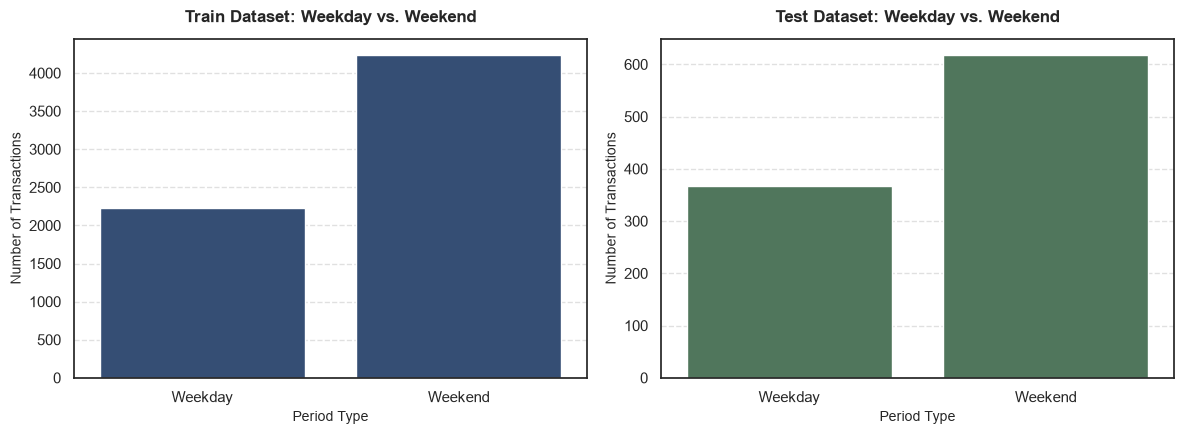

In [32]:

def plot_weekend_distribution_comparison(df_train, df_test):
  # Mapeamento para visualização
  train_plot = df_train.copy()
  train_plot['weekend_label'] = train_plot['is_weekend'].map(
      {0: 'Weekday', 1: 'Weekend'}
  )

  test_plot = df_test.copy()
  test_plot['weekend_label'] = test_plot['is_weekend'].map(
      {0: 'Weekday', 1: 'Weekend'}
  )

  fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=False)

  # Plot Treino
  ax1 = sns.countplot(
      data=train_plot,
      x='weekend_label',
      order=['Weekday', 'Weekend'],
      color='#2b4c7e',
      zorder=2,
      ax=axes[0],
  )
  ax1.set_axisbelow(True)
  axes[0].set_title(
      'Train Dataset: Weekday vs. Weekend',
      fontsize=12,
      fontweight='bold',
      pad=12,
  )
  axes[0].set_xlabel('Period Type', fontsize=10)
  axes[0].set_ylabel('Number of Transactions', fontsize=10)
  axes[0].grid(axis='y', linestyle='--', alpha=0.6, zorder=1)

  # Plot Teste
  ax2 = sns.countplot(
      data=test_plot,
      x='weekend_label',
      order=['Weekday', 'Weekend'],
      color='#4a7c59',
      zorder=2,
      ax=axes[1],
  )
  ax2.set_axisbelow(True)
  axes[1].set_title(
      'Test Dataset: Weekday vs. Weekend',
      fontsize=12,
      fontweight='bold',
      pad=12,
  )
  axes[1].set_xlabel('Period Type', fontsize=10)
  axes[1].set_ylabel('Number of Transactions', fontsize=10)
  axes[1].grid(axis='y', linestyle='--', alpha=0.6, zorder=1)

  plt.tight_layout()
  plt.show()


# Executar visualização comparativa
plot_weekend_distribution_comparison(df_train_clean, df_test_clean)


#### 2.5.2.2.
Following the successful extraction of structured temporal attributes (`purchase_month`, `purchase_dayofweek`, `purchase_quarter`, and `is_weekend`) and the subsequent removal of the redundant purchase_date string column to prevent dimensional explosion, we conduct an exploratory analysis of customer retention. 

Specifically, we examine whether the timing of the initial transaction influences customer re-engagement. The following analysis compares the 90-day repeat purchase rate (`repeat_purchase_90d`) between transactions initiated on business days versus weekends.

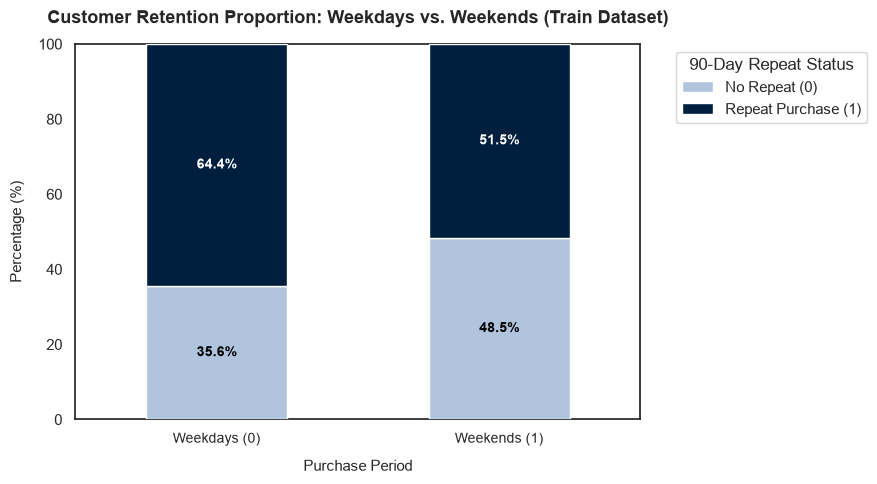

In [33]:

def plot_weekend_retention_proportion(
    dataframe, target_col='repeat_purchase_90d'
):
  # Verificar se o target existe no dataset antes de gerar o gráfico
  if target_col not in dataframe.columns:
    print(
        f"Note: '{target_col}' not found in the provided dataset. Chart skipped."
    )
    return

  # Prepare data for stacked bar chart: percentage of repeat purchases by weekend vs. weekday
  ct = (
      pd.crosstab(
          dataframe['is_weekend'], dataframe[target_col], normalize='index'
      )
      * 100
  )
  ct.index = ['Weekdays (0)', 'Weekends (1)']
  ct.columns = ['No Repeat (0)', 'Repeat Purchase (1)']

  # Graphic configuration: set the chart with visible grid lines behind the bars
  fig, ax = plt.subplots(figsize=(9, 5))
  sns.set_theme(style='white')

  ax.set_axisbelow(True)
  ax.yaxis.grid(True, color='#b0b0b0', linestyle='-', linewidth=0.8, zorder=0)

  ax = ct.plot(
      kind='bar',
      stacked=True,
      ax=ax,
      color=['#b0c4de', '#001f3f'],
      width=0.5,
      zorder=3,
  )

  plt.title(
      'Customer Retention Proportion: Weekdays vs. Weekends (Train Dataset)',
      fontsize=13,
      fontweight='bold',
      pad=15,
  )
  plt.xlabel('Purchase Period', fontsize=11, labelpad=10)
  plt.ylabel('Percentage (%)', fontsize=11, labelpad=10)
  plt.xticks(rotation=0, fontsize=10)
  plt.legend(
      title='90-Day Repeat Status',
      bbox_to_anchor=(1.05, 1),
      loc='upper left',
  )
  plt.ylim(0, 100)

  # Add percentage values inside the bars
  for n, c in enumerate(ct.columns):
    for i, val in enumerate(ct[c]):
      cumulative = ct.iloc[i, :n].sum() + val / 2
      if val > 5:
        ax.text(
            i,
            cumulative,
            f'{val:.1f}%',
            ha='center',
            va='center',
            color='white' if n == 1 else 'black',
            fontweight='bold',
            fontsize=10,
            zorder=4,
        )

  plt.tight_layout()
  plt.show()


# Executar exclusivamente para o dataset de TREINO
plot_weekend_retention_proportion(df_train_clean)


#### 2.5.2.3. Monthly Retention Dynamics (`purchase_month`)
To evaluate whether customer loyalty varies throughout the year, we analyze the 90-day repeat purchase rate across individual calendar months. This temporal decomposition allows us to identify if acquisition cohorts formed during specific seasonal periods exhibit stronger long-term engagement.

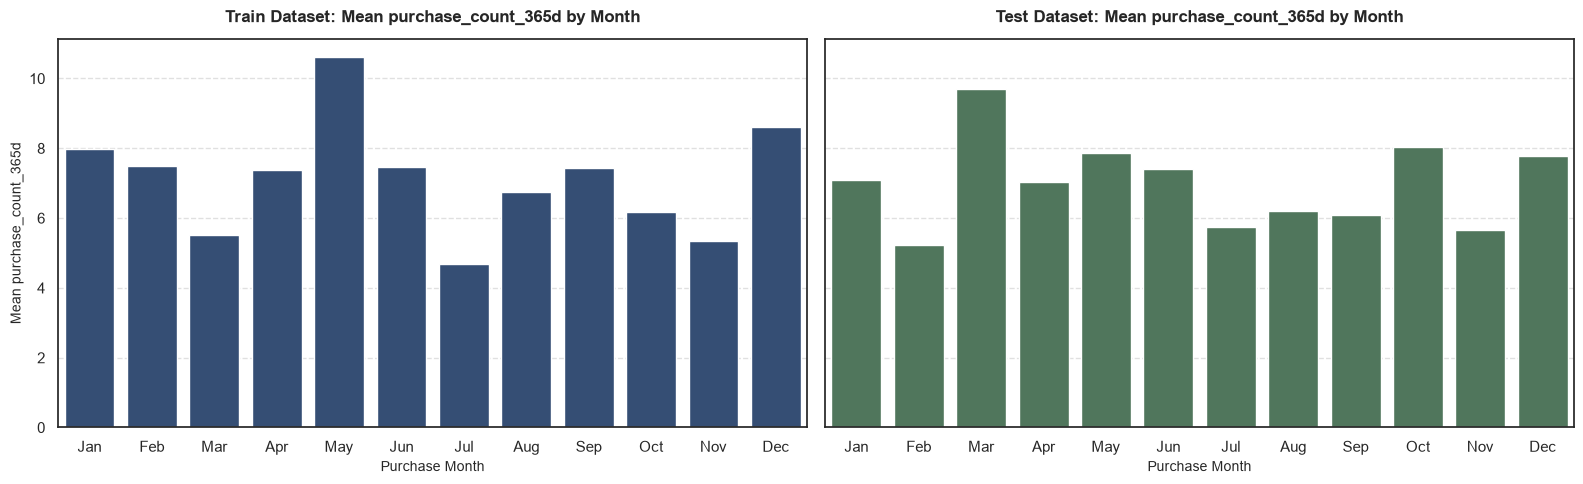

In [34]:

def plot_monthly_engagement_comparison(df_train, df_test, feature='purchase_count_365d'):
  month_map = {
      1: 'Jan', 2: 'Feb', 3: 'Mar', 4: 'Apr', 5: 'May', 6: 'Jun',
      7: 'Jul', 8: 'Aug', 9: 'Sep', 10: 'Oct', 11: 'Nov', 12: 'Dec',
  }
  month_order = [
      'Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
      'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec',
  ]

  # Process Train
  train_monthly = df_train.groupby('purchase_month')[feature].mean().reset_index()
  train_monthly['month_name'] = train_monthly['purchase_month'].map(month_map)

  # Process Test
  test_monthly = df_test.groupby('purchase_month')[feature].mean().reset_index()
  test_monthly['month_name'] = test_monthly['purchase_month'].map(month_map)

  fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)

  # Plot Train
  sns.barplot(
      data=train_monthly,
      x='month_name',
      y=feature,
      order=month_order,
      color='#2b4c7e',
      ax=axes[0],
  )
  axes[0].set_title(
      f'Train Dataset: Mean {feature} by Month',
      fontsize=12,
      fontweight='bold',
      pad=12,
  )
  axes[0].set_xlabel('Purchase Month', fontsize=10)
  axes[0].set_ylabel(f'Mean {feature}', fontsize=10)
  axes[0].grid(axis='y', linestyle='--', alpha=0.6)

  # Plot Test
  sns.barplot(
      data=test_monthly,
      x='month_name',
      y=feature,
      order=month_order,
      color='#4a7c59',
      ax=axes[1],
  )
  axes[1].set_title(
      f'Test Dataset: Mean {feature} by Month',
      fontsize=12,
      fontweight='bold',
      pad=12,
  )
  axes[1].set_xlabel('Purchase Month', fontsize=10)
  axes[1].set_ylabel(f'Mean {feature}', fontsize=10)
  axes[1].grid(axis='y', linestyle='--', alpha=0.6)

  plt.tight_layout()
  plt.show()


# Executar para comparar Treino e Teste
plot_monthly_engagement_comparison(df_train_clean, df_test_clean)


#### 2.5.2.4 Financial Impact Analysis: Transaction Value by Purchase Period (`is_weekend`)
To connect temporal patterns with financial metrics, we examine the distribution of transaction values (Total a Pagar) between business days and weekends. This verifies whether the operational differences observed in retention also reflect variations in basket size or purchasing power.

/var/folders/22/vdk97z556fv44cn_jt3l_1jc0000gn/T/ipykernel_46184/551558247.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
/var/folders/22/vdk97z556fv44cn_jt3l_1jc0000gn/T/ipykernel_46184/551558247.py:25: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


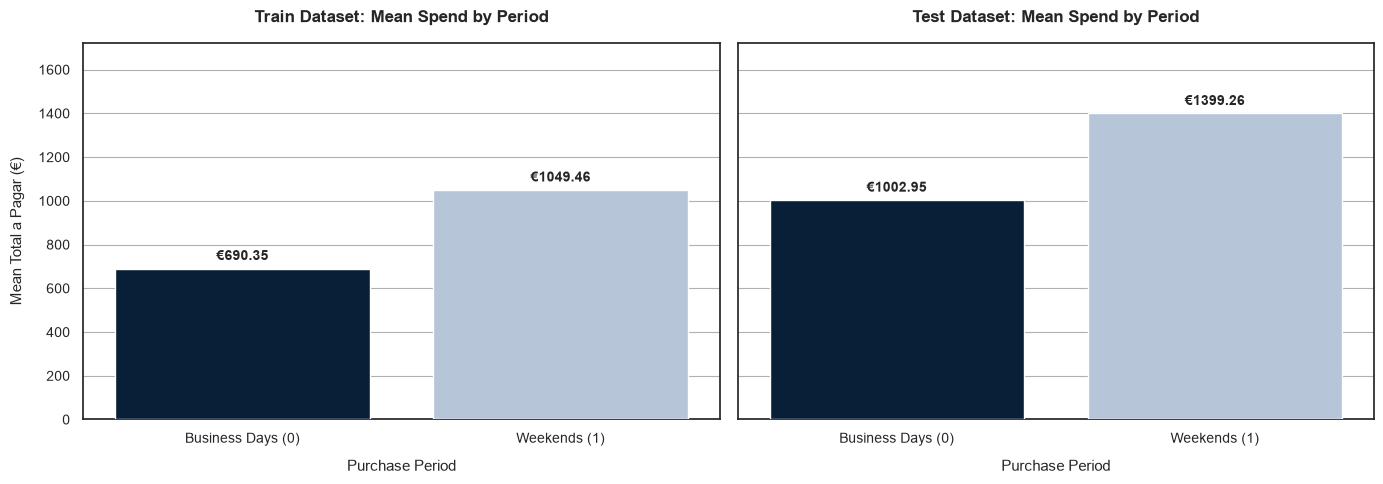

In [35]:

def plot_mean_transaction_value_comparison(df_train, df_test):
  # Prepare temporary copies with descriptive period labels
  train_fin = df_train.copy()
  train_fin['period_label'] = train_fin['is_weekend'].map(
      {0: 'Business Days (0)', 1: 'Weekends (1)'}
  )

  test_fin = df_test.copy()
  test_fin['period_label'] = test_fin['is_weekend'].map(
      {0: 'Business Days (0)', 1: 'Weekends (1)'}
  )

  # Configure figure with two side-by-side subplots
  fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
  sns.set_theme(style='white')

  # Data structure for iteration
  datasets = [(train_fin, 'Train Dataset', axes[0]), (test_fin, 'Test Dataset', axes[1])]

  for df_curr, title_prefix, ax in datasets:
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, color='#b0b0b0', linestyle='-', linewidth=0.8, zorder=0)

    # Bar plot representing the mean 'Total a Pagar' by period
    sns.barplot(
        data=df_curr,
        x='period_label',
        y='Total a Pagar',
        order=['Business Days (0)', 'Weekends (1)'],
        palette=['#001f3f', '#b0c4de'],
        ax=ax,
        zorder=3,
        errorbar=None,
    )

    ax.set_title(
        f'{title_prefix}: Mean Spend by Period',
        fontsize=12,
        fontweight='bold',
        pad=15,
    )
    ax.set_xlabel('Purchase Period', fontsize=11, labelpad=10)
    ax.set_ylabel('Mean Total a Pagar (€)', fontsize=11, labelpad=10)
    ax.tick_params(labelsize=10)

    # Add exact monetary values on top of the bars
    for p in ax.patches:
      height = p.get_height()
      if height > 0:
        ax.annotate(
            f'€{height:.2f}',
            (p.get_x() + p.get_width() / 2.0, height),
            ha='center',
            va='bottom',
            xytext=(0, 4),
            textcoords='offset points',
            fontsize=10,
            fontweight='bold',
            zorder=4,
        )

    # Dynamically expand the y-axis limit by 25% for clean margin inside frame
    y_max = ax.get_ylim()[1]
    ax.set_ylim(0, y_max * 1.25)

  plt.tight_layout()
  plt.show()


# Executar comparação entre Treino e Teste
plot_mean_transaction_value_comparison(df_train_clean, df_test_clean)

**Conclusions:** 
* **Temporal Feature Extraction & Validation**: Decomposing raw purchase timestamps into structured numerical components (purchase_year, purchase_month, purchase_day, purchase_dayofweek, purchase_quarter, and is_weekend) successfully operationalizes calendar-based dynamics. Translating raw temporal data into explicit features equips tree-based models with clear, partitionable boundaries to accurately capture seasonal peaks and weekly customer purchasing habits.

* Additionally, the original date column (purchase_date) was removed prior to categorical encoding to prevent dimensional explosion and avoid the redundant creation of binary variables for each individual date, as all relevant structured temporal information had already been successfully extracted into dedicated numerical attributes.

* **Graph - `Transaction Distribution: Weekday vs. Weekend`:** The transaction distribution chart reveals a pronounced difference in purchasing volume, showing that weekend transactions (approximately 4,200) are significantly higher than weekday transactions (approximately 2,200). This empirical insight confirms that customer purchasing behavior varies substantially between workdays and weekends, validating the inclusion of the is_weekend binary feature.

* **Graph - `Customer Retention Proportion: Weekdays vs. Weekends`:** The stacked distribution illustrates that transactions initiated on business days exhibit a 90-day repeat purchase rate of 64.4%, whereas transactions conducted on weekends record a rate of 51.5%.   Behavioral Interpretation: This divergence highlights that weekday buyers demonstrate a more regular and recurring acquisition behavior (typical of corporate procurement processes or routine purchases), contrasting with the more sporadic and occasional nature of weekend buyers.   Predictive Relevance: This clear distinction in retention patterns validates the utility of including the is_weekend feature, providing a robust behavioral signal for subsequent predictive models without introducing high-cardinality noise.

* **Graph - `90-Day Repeat Purchase Rate by Purchase Month`:** 
    * The monthly breakdown reveals noticeable fluctuations in the 90-day repeat purchase rate across different times of the year, confirming that acquisition timing influences customer lifecycle value.
    * Identifying specific high-retention months allows the organization to optimize marketing acquisition budgets, focusing resources on periods that naturally attract more loyal customer cohorts.

* **Graph - `Average Transaction Value (Total a Pagar) by Purchase Period`:**
    * The analysis of the average transaction value (Total a Pagar) indicates whether purchasing power or basket sizes differ between business days and weekends, complementing the behavioral retention insights.
    * Understanding that transaction values remain relatively consistent (or fluctuate) between weekdays and weekends provides a solid foundation for timing promotional campaigns and optimizing revenue streams without disrupting customer purchasing habits.

____________________________________________________________________________________________________________________________________________________________________________________

## 2.6. Final Validation and Audit of Residual Missing Values

In [36]:
import pandas as pd

inputFileTrain = "../../../data/trainDataset/train_2_5_1.csv"
inputFileTest = "../../../data/testDataset/test_2_5_1.csv"


def check_remaining_missing_values(input_file, dataset_label="Dataset"):
  # Load the dataset
  df = pd.read_csv(input_file)

  # Calculate total missing values per column and filter only those with > 0 nulls
  missing_counts = df.isnull().sum()
  missing_counts = missing_counts[missing_counts > 0]

  print(f"=== REMAINING MISSING VALUES ({dataset_label}) ===")
  if len(missing_counts) > 0:
    print(missing_counts)
    print(f"\nTotal columns with nulls: {len(missing_counts)}")
  else:
    print(
        f"Congratulations! There are no missing values left in the"
        f" {dataset_label} dataset."
    )
  print("-" * 50 + "\n")

  return missing_counts


# Executar a verificação para Treino e Teste
missing_train = check_remaining_missing_values(
    inputFileTrain, dataset_label="Train"
)
missing_test = check_remaining_missing_values(
    inputFileTest, dataset_label="Test"
)

=== REMAINING MISSING VALUES (Train) ===
spend_365d          210
payment_type        195
salesperson         194
transport_method    196
warehouse           195
dtype: int64

Total columns with nulls: 5
--------------------------------------------------

=== REMAINING MISSING VALUES (Test) ===
spend_365d          32
payment_type        30
salesperson         30
transport_method    30
warehouse           30
dtype: int64

Total columns with nulls: 5
--------------------------------------------------



**Conclusion:**
The execution of the missing value audit on the actual dataset revealed that 5 columns still contain missing data.
The outcome indicates that the missing values treatment process still needs some adjustments. Since most Machine Learning algorithms require null-free feature matrices, it is essential to apply the final imputation phase—filling spending history with appropriate neutral values and operational categorical variables with a dedicated category (e.g., "Unknown")—to ensure structural data integrity before moving forward with predictive modeling.

These final adjustments to address the residual missing values will be implemented in the next step by joining the training dataset with the clients table, allowing us to recover and enrich the missing data directly from each client's centralized profile and history.